# Semaine 1 : Introduction aux Systèmes Temps Réel

## Objectifs pédagogiques
- Comprendre ce qu'est un système temps réel et ses contraintes.
- Distinguer les systèmes temps réel dur, mou et ferme.
- Identifier les caractéristiques de déterminisme et de sûreté de fonctionnement.
- Simuler une tâche périodique simple pour visualiser le respect des échéances.

## 1. Définition d'un système temps réel
Un **système temps réel** est un système dont la **correction** ne dépend pas seulement de la justesse des résultats calculés, mais aussi du **moment** où ces résultats sont produits. Le non-respect d'une contrainte temporelle (**échéance**) peut entraîner une défaillance du système.

**Exemples** :
- Contrôle de vol d'un avion (avionique)
- ABS dans une automobile
- Bras robotique industriel
- Système de régulation cardiaque (pacemaker)

## 2. Exemples de systèmes temps réel
### Avionique
- Gestion des commandes de vol, navigation, communication.
- Contraintes : latence très faible, haute fiabilité, certification stricte (DO-178C).

### Automobile
- ABS, contrôle moteur, airbags, assistance à la conduite.
- Contraintes : temps de réponse court (quelques ms), robustesse aux perturbations.

### Robotique
- Asservissement de position, vision, planification de trajectoire.
- Contraintes : périodicité précise, synchronisation entre capteurs et actionneurs.

## 3. Contraintes temporelles
Les performances d'un système temps réel sont décrites par plusieurs grandeurs fondamentales :
- **Échéance (deadline)** : instant au plus tard où la tâche doit avoir terminé son exécution.
- **Période (period)** : intervalle entre deux activations successives d'une tâche périodique.
- **Temps d'exécution au pire des cas (WCET / worst-case execution time)** : durée nécessaire au processeur pour exécuter la tâche sans interruption.
- **Latence** (temps de réponse) : délai entre l'occurrence de l'événement déclencheur et la réponse du système.
- **Jitter** : variation du temps de réponse ou de l'activation d'une tâche, qui peut nuire à la stabilité temporelle.

Un système temps réel doit garantir que **toutes les échéances sont respectées**, sans entraîner de dépassement imprévisible ni de comportement non déterministe.

## 4. Classification des systèmes temps réel
| Type | Conséquence d'un dépassement d'échéance | Exemple |
|------|------------------------------------------|---------|
| **Temps réel dur** | Catastrophique (perte de vie, dégâts matériels) | Commande de vol, pacemaker |
| **Temps réel ferme** | Résultat inutile ou périmé, mais sans catastrophe | Streaming vidéo, réservation en ligne |
| **Temps réel mou** | Résultat dégradé, mais encore utilisable | Jeu vidéo, interface graphique |

> Remarque : la différence principale entre les catégories réside dans la gravité de la violation d'échéance.

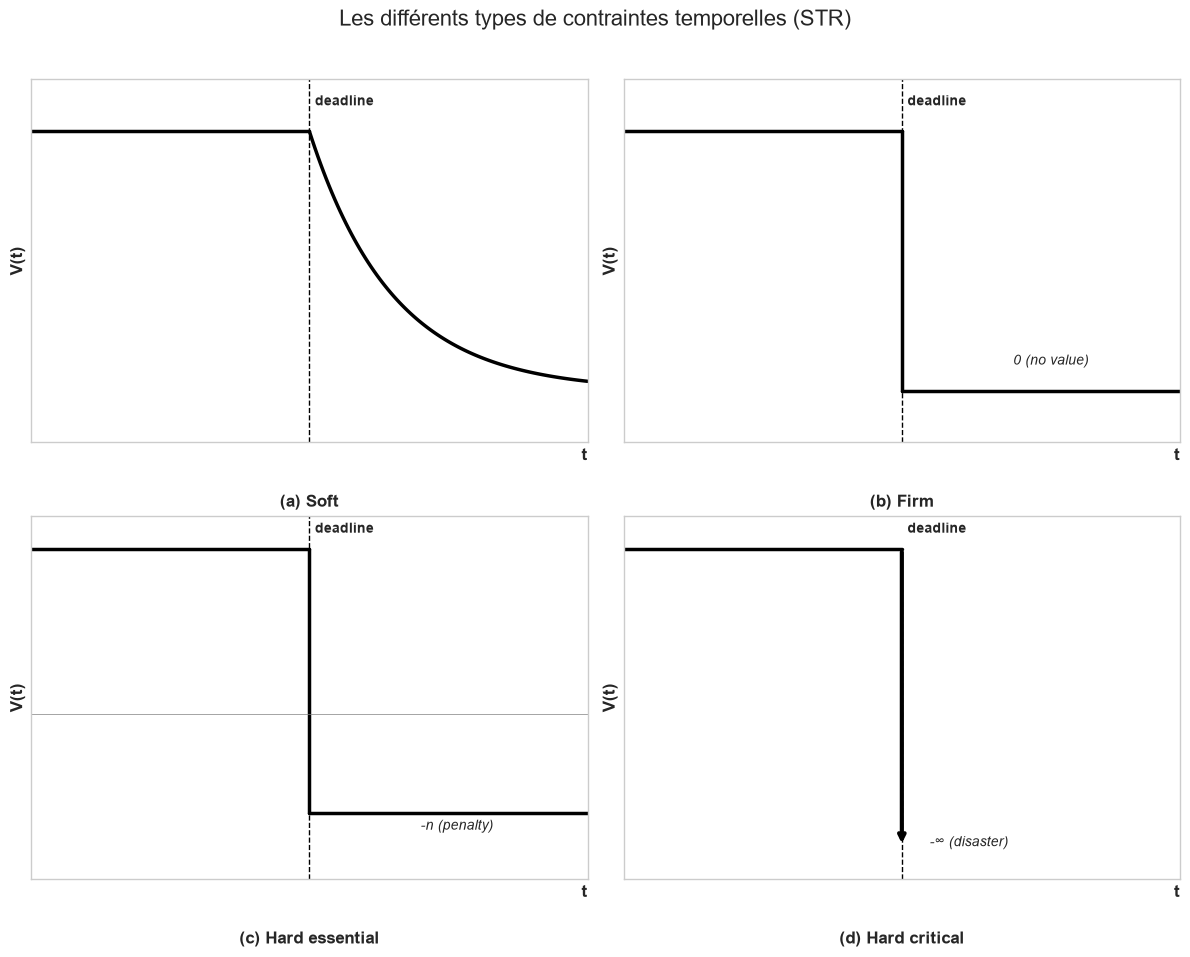

In [9]:
import matplotlib.pyplot as plt
import numpy as np

# Configuration du style pour un rendu propre dans Jupyter
%matplotlib inline
plt.style.use('seaborn-v0_8-whitegrid')

# Création de la figure et des sous-graphiques (2x2)
fig, axs = plt.subplots(2, 2, figsize=(12, 10))
fig.suptitle("Les différents types de contraintes temporelles (STR)", fontsize=16, y=0.95)

# Paramètres communs
t = np.linspace(0, 10, 500)
deadline = 5
V_max = 5

# ---------------------------------------------------------
# (a) Soft Deadline
# ---------------------------------------------------------
ax = axs[0, 0]
# Partie constante avant la deadline
ax.plot([0, deadline], [V_max, V_max], 'k-', linewidth=2.5)
# Partie décroissante (exponentielle) après la deadline
t_soft = np.linspace(deadline, 10, 100)
v_soft = V_max * np.exp(-(t_soft - deadline) / 1.5) # Décroissance progressive
ax.plot(t_soft, v_soft, 'k-', linewidth=2.5)

# Ligne pointillée verticale pour la deadline
ax.axvline(x=deadline, color='k', linestyle='--', linewidth=1)
ax.text(deadline + 0.1, V_max + 0.5, "deadline", fontsize=10, fontweight='bold')

# Mise en forme des axes
ax.set_title("(a) Soft", y=-0.2, fontsize=12, fontweight='bold')
ax.set_ylabel("V(t)", fontsize=12, fontweight='bold')
ax.set_xlabel("t", fontsize=12, fontweight='bold', loc='right')
ax.set_ylim(-1, 6)
ax.set_xlim(0, 10)
ax.set_yticks([]) # Cacher les graduations Y pour ressembler au schéma
ax.set_xticks([]) # Cacher les graduations X

# ---------------------------------------------------------
# (b) Firm Deadline
# ---------------------------------------------------------
ax = axs[0, 1]
# Partie constante
ax.plot([0, deadline], [V_max, V_max], 'k-', linewidth=2.5)
# Chute verticale à 0
ax.plot([deadline, deadline], [V_max, 0], 'k-', linewidth=2.5)
# Ligne à 0 après
ax.plot([deadline, 10], [0, 0], 'k-', linewidth=2.5)

# Annotation
ax.axvline(x=deadline, color='k', linestyle='--', linewidth=1)
ax.text(deadline + 0.1, V_max + 0.5, "deadline", fontsize=10, fontweight='bold')
ax.text(7, 0.5, "0 (no value)", fontsize=10, style='italic')

# Mise en forme
ax.set_title("(b) Firm", y=-0.2, fontsize=12, fontweight='bold')
ax.set_ylabel("V(t)", fontsize=12, fontweight='bold')
ax.set_xlabel("t", fontsize=12, fontweight='bold', loc='right')
ax.set_ylim(-1, 6)
ax.set_xlim(0, 10)
ax.set_yticks([])
ax.set_xticks([])

# ---------------------------------------------------------
# (c) Hard Essential
# ---------------------------------------------------------
ax = axs[1, 0]
# Partie constante
ax.plot([0, deadline], [V_max, V_max], 'k-', linewidth=2.5)
# Chute verticale vers une valeur négative (-n)
penalty = -3
ax.plot([deadline, deadline], [V_max, penalty], 'k-', linewidth=2.5)
# Ligne constante négative après
ax.plot([deadline, 10], [penalty, penalty], 'k-', linewidth=2.5)

# Annotation
ax.axvline(x=deadline, color='k', linestyle='--', linewidth=1)
ax.text(deadline + 0.1, V_max + 0.5, "deadline", fontsize=10, fontweight='bold')
ax.text(7, penalty - 0.5, "-n (penalty)", fontsize=10, style='italic')

# Mise en forme
ax.set_title("(c) Hard essential", y=-0.2, fontsize=12, fontweight='bold')
ax.set_ylabel("V(t)", fontsize=12, fontweight='bold')
ax.set_xlabel("t", fontsize=12, fontweight='bold', loc='right')
ax.set_ylim(-5, 6)
ax.set_xlim(0, 10)
ax.set_yticks([])
ax.set_xticks([])
# Ajouter une ligne de zéro visuelle
ax.axhline(y=0, color='gray', linewidth=0.5)

# ---------------------------------------------------------
# (d) Hard Critical
# ---------------------------------------------------------
ax = axs[1, 1]
# Partie constante
ax.plot([0, deadline], [V_max, V_max], 'k-', linewidth=2.5)

# Flèche verticale vers le bas (Disaster)
# On dessine une ligne épaisse avec une flèche
ax.annotate('', xy=(deadline, -4), xytext=(deadline, V_max),
            arrowprops=dict(arrowstyle='->', color='black', lw=3))

# Annotation
ax.axvline(x=deadline, color='k', linestyle='--', linewidth=1, ymax=0.8)
ax.text(deadline + 0.1, V_max + 0.5, "deadline", fontsize=10, fontweight='bold')
ax.text(deadline + 0.5, -4, "-∞ (disaster)", fontsize=10, style='italic')

# Mise en forme
ax.set_title("(d) Hard critical", y=-0.2, fontsize=12, fontweight='bold')
ax.set_ylabel("V(t)", fontsize=12, fontweight='bold')
ax.set_xlabel("t", fontsize=12, fontweight='bold', loc='right')
ax.set_ylim(-5, 6)
ax.set_xlim(0, 10)
ax.set_yticks([])
ax.set_xticks([])

# Ajustement de l'espacement entre les graphiques
plt.tight_layout()
plt.subplots_adjust(top=0.88)
plt.show()

## 5. Déterminisme et sûreté de fonctionnement
- **Déterminisme** : capacité du système à fournir une réponse dans un intervalle de temps borné et prévisible. Un système temps réel doit être déterministe temporellement afin que les échéances soient garanties.
- **Sûreté de fonctionnement** : ensemble de propriétés qui assurent la confiance dans le comportement du système :
  - *Fiabilité* : probabilité de fonctionner sans défaillance sur une durée donnée.
  - *Disponibilité* : aptitude à être en état de fonctionnement lorsque cela est nécessaire.
  - *Sécurité* : absence de conséquences catastrophiques en cas de défaillance.
  - *Maintenabilité* : facilité de réparation, de test et de mise à jour.

En pratique, un système temps réel n'est utile que s'il est à la fois rapide, sûr et prévisible.

---
## Activité 1 : Classifier des systèmes
Pour chacun des systèmes suivants, indiquez s'il s'agit d'un système temps réel **dur**, **ferme** ou **mou** et justifiez brièvement.

1. Système de freinage ABS d'une voiture.
2. Lecteur vidéo en streaming (ex. Netflix).
3. Système de navigation GPS dans un smartphone.
4. Contrôleur de température d'un four industriel.
5. Jeu vidéo multijoueur en ligne.

**Répondez dans la cellule Markdown ci-dessous.**

 Réponses: 

1: Système de freinage ABS d'une voiture
Réponse : Temps réel dur (Hard Real-Time).

Justification : Le système ABS doit réagir immédiatement pour éviter le blocage des roues pendant le freinage. Le non-respect de l'échéance peut provoquer un accident et mettre des vies en danger

2-Lecteur vidéo en streaming (Netflix)
Réponse : Temps réel ferme (Firm Real-Time).

Justification : Les données vidéo doivent arriver dans les délais pour être affichées correctement. Une donnée reçue trop tard devient inutile, car elle correspond à une image qui aurait déjà dû être affichée

3-Système de navigation GPS dans un smartphone
Réponse : Temps réel mou .

Justification : Le système doit fournir les informations de navigation rapidement. Un retard dans l'affichage de la position ou de l'itinéraire peut dégrader le service, mais ne provoque pas nécessairement une défaillance catastrophique

4-Contrôleur de température d'un four industriel
Réponse : Temps réel dur .

Justification : Le contrôleur doit respecter les délais de mesure et de régulation de la température. Un retard important peut provoquer une surchauffe, endommager les équipements ou mettre les personnes en danger.

5-Jeu vidéo multijoueur en ligne
Réponse : Temps réel mou .

Justification : Les actions des joueurs doivent être traitées rapidement pour garantir une bonne expérience de jeu. Un retard peut provoquer des ralentissements ou des décalages, mais le résultat reste généralement utilisable.

---
## Activité 2 : Simulation d'une tâche périodique

Une tâche périodique est caractérisée par :
- **C** : temps d'exécution au pire des cas (constant) ou capacité de la tâche
- **T** : période (intervalle entre deux activations)
- **D** : échéance relative (souvent D = T) appelé encore delai critique
- **d** : échéance absolue (d = r + D), r = instant d'activation de la tache périodique

La simulation ci-dessous modélise l'exécution d'une tâche sur un processeur unique. La tâche est relâchée (réveillée) à chaque période et doit terminer avant son échéance. Le processeur exécute la tâche de manière continue dès qu'elle est prête.

Modifiez les valeurs de `C` et `T` et observez si la tâche respecte toutes ses échéances.

In [9]:
def simuler_tache_periodique(C, T, duree_simulation):
    """
    Simule une tâche périodique de temps d'exécution C et période T.
    Retourne le statut de l'échéance de chaque instance libérée.
    """
    if C <= 0 or T <= 0 or duree_simulation <= 0:
        raise ValueError("C, T et duree_simulation doivent être strictement positifs")

    temps = 0
    prochaine_activation = 0
    instances = []
    resultats = []

    while temps < duree_simulation:
        # Chaque activation crée une nouvelle instance, conservée dans la file.
        if temps >= prochaine_activation:
            instances.append({
                "echeance": prochaine_activation + T,
                "reste": C,
            })
            prochaine_activation += T

        # Une seule instance s'exécute à la fois, dans l'ordre d'activation.
        if instances:
            instance = instances[0]
            instance["reste"] -= 1
            if instance["reste"] == 0:
                fin_execution = temps + 1
                statut = "Respectée" if fin_execution <= instance["echeance"] else "Violée"
                resultats.append(statut)
                instances.pop(0)

        temps += 1

    # Toute instance encore en attente a nécessairement dépassé son échéance
    # ou ne peut pas être évaluée dans la durée de simulation.
    resultats.extend("Violée" for _ in instances)
    return resultats

# Paramètres à modifier
C = 5  # temps d'exécution
T = 7 # période
duree = 20

res = simuler_tache_periodique(C, T, duree)
print(f"Résultats pour C={C}, T={T} :")
for i, r in enumerate(res, 1):
    print(f"  Instance {i}: échéance {r}")

Résultats pour C=5, T=7 :
  Instance 1: échéance Respectée
  Instance 2: échéance Respectée
  Instance 3: échéance Respectée


In [12]:
# Vérification du cas C > T et de l'échéance atteinte exactement.
assert simuler_tache_periodique(6, 5, 20) == ["Violée"] * 4
assert simuler_tache_periodique(5, 5, 15) == ["Respectée"] * 3
print("Tests C > T et C = T : OK")

Tests C > T et C = T : OK


---
## 6. Représentation temporelle avec Matplotlib

Le graphique ci-dessous représente l'exécution de la tâche pour `C = 3` et `T = 5`. Chaque activation démarre aux instants 0, 5, 10 et 15 ; les trois unités de temps d'exécution sont suivies d'une échéance respectée.

Modifiez les valeurs de `C` et `T` dans la cellule Python pour observer l'impact sur l'ordonnancement.

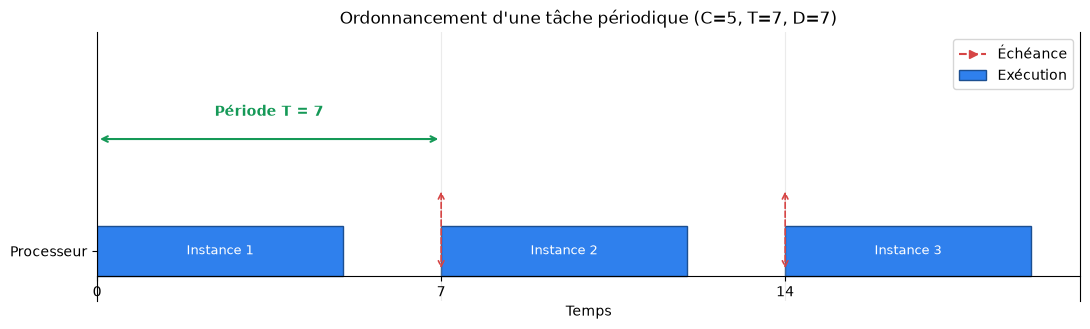

In [3]:
import matplotlib.pyplot as plt

# Paramètres de la tâche
C = 5  # temps d'exécution
T = 7   # période
D = T   # échéance relative
duree = 20

activations = list(range(0, duree, T))
hauteur_execution = 0.2
y_base = 0
y_execution = y_base + hauteur_execution / 2
y_fleche_haut = 0.35
y_periode = 0.55

fig, ax = plt.subplots(figsize=(11, 3.4))

for numero, activation in enumerate(activations, 1):
    fin_execution = min(activation + C, duree)
    ax.barh(
        y=y_execution,
        width=fin_execution - activation,
        left=activation,
        height=hauteur_execution,
        color="#2f80ed",
        edgecolor="#1c4f91",
        label="Exécution" if numero == 1 else "",
    )
    ax.text(
        activation + (fin_execution - activation) / 2,
        y_execution,
        f"Instance {numero}",
        ha="center",
        va="center",
        color="white",
        fontsize=9,
    )

    echeance = activation + D
    style_fleche = "<->" if D == T else "-|>"
    ax.annotate(
        "",
        xy=(echeance, y_base + 0.02),
        xytext=(echeance, y_fleche_haut),
        arrowprops={
            "arrowstyle": style_fleche,
            "color": "#d64545",
            "linestyle": "--",
            "linewidth": 1.2,
        },
    )

ax.annotate(
    "",
    xy=(T, y_periode),
    xytext=(0, y_periode),
    arrowprops={"arrowstyle": "<->", "color": "#159957", "linewidth": 1.5},
)
ax.text(
    T / 2,
    y_periode + 0.08,
    f"Période T = {T}",
    ha="center",
    va="bottom",
    color="#159957",
    fontweight="bold",
)

# Entrées fictives pour conserver les échéances dans la légende
ax.plot([], [], color="#d64545", linestyle="--", marker=">", label="Échéance")

# L'axe des abscisses coïncide avec le bas des rectangles
ax.spines["bottom"].set_position(("data", y_base))
ax.spines["top"].set_visible(False)
ax.set_xlim(0, duree)
ax.set_ylim(-0.1, 0.98)
ax.set_yticks([y_execution])
ax.set_yticklabels(["Processeur"])
ax.set_xticks(range(0, duree + 1, T))
ax.set_xlabel("Temps")
ax.set_title(f"Ordonnancement d'une tâche périodique (C={C}, T={T}, D={D})")
ax.grid(axis="x", alpha=0.25)
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

---
## Activité 3 : Simulation de deux tâches périodiques

On considère deux tâches périodiques exécutées sur un processeur unique :

- **Tâche A** : temps d'exécution `C₁` et période `T₁` ;
- **Tâche B** : temps d'exécution `C₂` et période `T₂`.

À chaque instant, le processeur choisit parmi les tâches prêtes celle dont la période est la plus courte (ordonnancement Rate Monotonic). La simulation affiche l'utilisation du processeur et indique si les échéances sont respectées.

Modifiez les valeurs de `C₁`, `T₁`, `C₂` et `T₂`, puis observez l'effet sur l'ordonnancement.

Utilisation processeur : 100.0%
Tâche A activée à t=0 : échéance respectée
Tâche B activée à t=0 : échéance respectée
Tâche A activée à t=7 : échéance respectée
Tâche B activée à t=7 : échéance respectée
Tâche A activée à t=14 : échéance respectée
Tâche B activée à t=14 : échéance respectée
Tâche A activée à t=21 : échéance respectée
Tâche B activée à t=21 : échéance respectée
Tâche A activée à t=28 : échéance respectée
Tâche B activée à t=28 : échéance respectée
Tâche A activée à t=35 : échéance respectée
Tâche B activée à t=35 : échéance violée


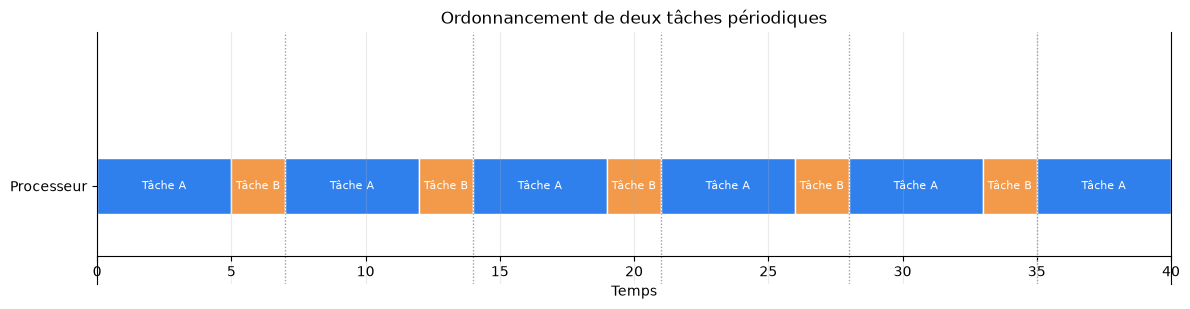

In [4]:
import matplotlib.pyplot as plt

# Paramètres modifiables des deux tâches
C1, T1 = 5, 7
C2, T2 = 2, 7
duree_simulation = 40

taches = {
    "Tâche A": {"C": C1, "T": T1, "couleur": "#2f80ed"},
    "Tâche B": {"C": C2, "T": T2, "couleur": "#f2994a"},
}

utilisation = sum(parametres["C"] / parametres["T"] for parametres in taches.values())
print(f"Utilisation processeur : {utilisation:.1%}")

instances = []
ordonnancement = []

for temps in range(duree_simulation):
    # Relâchement des nouvelles instances
    for nom, parametres in taches.items():
        if temps % parametres["T"] == 0:
            instances.append({
                "nom": nom,
                "T": parametres["T"],
                "activation": temps,
                "echeance": temps + parametres["T"],
                "reste": parametres["C"],
                "fin": None,
            })

    instances_pretes = [
        instance
        for instance in instances
        if instance["activation"] <= temps and instance["reste"] > 0
    ]

    if instances_pretes:
        # Rate Monotonic : la période la plus courte est prioritaire
        instance_active = min(instances_pretes, key=lambda instance: instance["T"])
        instance_active["reste"] -= 1
        ordonnancement.append(instance_active["nom"])
        if instance_active["reste"] == 0:
            instance_active["fin"] = temps + 1
    else:
        ordonnancement.append("Inactif")

# Bilan des échéances
for instance in instances:
    instance["respectee"] = (
        instance["fin"] is not None
        and instance["fin"] <= instance["echeance"]
    )
    etat = "respectée" if instance["respectee"] else "violée"
    print(
        f"{instance['nom']} activée à t={instance['activation']} : "
        f"échéance {etat}"
    )

# Construction des segments contigus du diagramme temporel
segments = []
debut_segment = 0
nom_segment = ordonnancement[0]

for instant in range(1, duree_simulation + 1):
    changement = instant == duree_simulation or ordonnancement[instant] != nom_segment
    if changement:
        segments.append((nom_segment, debut_segment, instant - debut_segment))
        if instant < duree_simulation:
            debut_segment = instant
            nom_segment = ordonnancement[instant]

fig, ax = plt.subplots(figsize=(12, 3.2))

for nom, debut, largeur in segments:
    couleur = "#d9d9d9" if nom == "Inactif" else taches[nom]["couleur"]
    ax.barh(
        y=0.25,
        width=largeur,
        left=debut,
        height=0.2,
        color=couleur,
        edgecolor="white",
    )
    if nom != "Inactif":
        ax.text(
            debut + largeur / 2,
            0.25,
            nom,
            ha="center",
            va="center",
            color="white",
            fontsize=8,
        )

for nom, parametres in taches.items():
    for echeance in range(parametres["T"], duree_simulation + 1, parametres["T"]):
        ax.axvline(
            echeance,
            color=parametres["couleur"],
            linestyle=":",
            linewidth=0.9,
            alpha=0.7,
        )

ax.spines["bottom"].set_position(("data", 0))
ax.spines["top"].set_visible(False)
ax.set_xlim(0, duree_simulation)
ax.set_ylim(-0.1, 0.8)
ax.set_yticks([0.25])
ax.set_yticklabels(["Processeur"])
ax.set_xticks(range(0, duree_simulation + 1, 5))
ax.set_xlabel("Temps")
ax.set_title("Ordonnancement de deux tâches périodiques")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

**Questions :**
1. Que se passe-t-il si C > T ?
2. Que se passe-t-il si C = T ?
3. Que se passe-t-il si C < T ?
4. À partir de quelle valeur de C (pour une période T donnée) l'ordonnancement devient-il impossible ?

Les Réponses:

1-Lorsque le temps d'exécution C est supérieur à la période T, une tâche n'a pas terminé son exécution avant l'arrivée de la prochaine activation.

Les instances s'accumulent dans la file d'attente et les échéances ne sont pas respectées.

Donc, l'ordonnancement est impossible

2-Lorsque C est égal à T, la tâche termine son exécution exactement à son échéance.

Toutes les échéances sont respectées, mais le processeur est utilisé à 100 % par cette tâche et ne possède aucune marge de temps libre.

3-Lorsque C est inférieur à T, la tâche termine son exécution avant la prochaine activation.

Toutes les échéances sont respectées et le processeur dispose d'un temps libre entre deux exécutions.

4-Pour une tâche périodique avec une échéance D = T, l'ordonnancement devient impossible lorsque :
C>T



---
## Exercice 1 : Questions de compréhension

1. Donnez une définition d'un système temps réel.
2. Expliquez la différence entre temps réel dur et temps réel mou avec un exemple pour chacun.
3. Qu'est-ce que le déterminisme temporel et pourquoi est-il important dans un système temps réel ?
4. Citez au moins trois domaines d'application des systèmes temps réel.
5. Quels sont les paramètres temporels principaux d'une tâche périodique ? Définissez-les.

Les Réponses:

1-Un système temps réel est un système informatique dont la correction dépend non seulement de la justesse du résultat, mais également du moment où ce résultat est produit.

Il doit respecter des contraintes temporelles appelées échéances (deadlines). Le non-respect de ces échéances peut entraîner une défaillance du système.

2-Temps réel dur (Hard Real-Time) : le respect des échéances est obligatoire. Leur dépassement peut provoquer des conséquences catastrophiques.

Exemple : le système de freinage ABS d'une voiture.

Temps réel mou (Soft Real-Time) : le respect des échéances est souhaitable, mais leur dépassement entraîne uniquement une dégradation des performances du système.

Exemple : un jeu vidéo.


3-Le déterminisme temporel est la capacité d'un système à produire une réponse dans un intervalle de temps connu et prévisible.

Il est important car il permet de garantir le respect des échéances et d'assurer un fonctionnement fiable et prévisible du système.

4-Les systèmes temps réel sont utilisés dans plusieurs domaines :
- Aéronautique : commande de vol et navigation des avions.

- Automobile : ABS, airbags et contrôle moteur.

- Robotique : commande des mouvements des robots industriels.

- Médical : pacemakers et équipements de surveillance médicale.

5-Les principaux paramètres temporels d'une tâche périodique sont :
- C (Temps d'exécution) : durée nécessaire pour exécuter une tâche sur le processeur, généralement considérée dans le pire des cas (WCET).

- T (Période) : intervalle de temps entre deux activations successives de la tâche.

- D (Échéance relative) : durée maximale autorisée entre l'activation et la fin de l'exécution de la tâche.

- r (Instant d'activation) : instant auquel une tâche est activée.

- d (Échéance absolue) : instant limite auquel la tâche doit terminer son exécution.

La relation entre l'échéance absolue et l'échéance relative est : d=D+r

---
## Exercice 2 : Analyse d'un ordonnancement simple (après week4)

Considérez une tâche périodique avec les caractéristiques suivantes :
- Temps d'exécution C = 2 ms
- Période T = 10 ms
- Échéance D = 10 ms

1. Calculez le taux d'utilisation processeur de cette tâche.
2. Combien d'instances de cette tâche peuvent être exécutées en une seconde ?
3. Si le processeur exécute également une autre tâche périodique de C = 4 ms et T = 20 ms, le système est-il ordonnançable avec l'algorithme Rate Monotonic (RM) ? Justifiez en utilisant la condition suffisante de Liu & Layland.

**Répondez dans la cellule Markdown ci-dessous.**

Les Réponses:

1-Le taux d'utilisation du processeur est calculé par la formule :
U=C/T
donc U=2/10=0.2=20%

2-On sait que :
1s=1000ms

Le nombre d'instances est donné par : N=1000/T
donc N=1000/10=100 instances

3-U=C1/T1+C2/T2
donc U=2/10+4/20=0.2+0.2=0.4=40%

D'après la condition suffisante de Liu & Layland : U<=2*(2**(1/2)-1)=0.8284=82.84%
donc 40%<=82.84%

Alors Le système est ordonnançable avec l'algorithme Rate Monotonic (RM), car son taux d'utilisation total (40 %) est inférieur à la limite de Liu & Layland (82,84 %).

La condition suffisante est donc vérifiée.

---
## TP : Prise en main d'un RTOS (FreeRTOS)

### Objectif
Familiarisez-vous avec l'environnement de développement d'un système d'exploitation temps réel (RTOS) en créant deux tâches simples qui s'exécutent de manière périodique.

### Matériel / Logiciel
- Carte de développement (ex. STM32 Nucleo, ESP32) ou simulateur (ex. QEMU, Wokwi).
- FreeRTOS installé (ou tout autre RTOS : Zephyr, RTX, etc.).
- Environnement de compilation (gcc, PlatformIO, STM32CubeIDE, etc.).

### Étapes
1. Créez un projet avec FreeRTOS.
2. Définissez deux tâches :
   - **Tâche 1** : clignote une LED toutes les 500 ms.
   - **Tâche 2** : incrémente un compteur et l'affiche sur la console toutes les 1 s.
3. Configurez les priorités des tâches (par exemple, tâche 1 priorité haute, tâche 2 priorité basse).
4. Lancez le programme et vérifiez que les deux tâches s'exécutent correctement.
5. Modifiez les périodes et les priorités, observez l'impact sur l'exécution.

### Questions
- Comment le RTOS gère-t-il l'alternance entre les deux tâches ?
- Que se passe-t-il si les deux tâches ont la même priorité ?
- Comment pouvez-vous mesurer le temps d'exécution de chaque tâche ?

Les Réponses:

1-Le RTOS utilise un ordonnanceur (Scheduler) pour gérer l'exécution des tâches.

Il attribue le processeur à la tâche prête ayant la priorité la plus élevée. Lorsqu'une tâche se bloque ou termine son temps d'exécution, le processeur peut être attribué à une autre tâche.

Ainsi, FreeRTOS permet l'exécution de plusieurs tâches de manière organisée et assure le respect de leurs priorités.

2-Si les deux tâches ont la même priorité, FreeRTOS peut utiliser le partage du temps processeur (Time Slicing) pour alterner entre elles.

Chaque tâche dispose d'un intervalle de temps pour s'exécuter. Lorsqu'une tâche se bloque ou termine son délai d'attente, l'autre peut prendre le processeur.

Le comportement du partage temporel dépend de la configuration de FreeRTOS

3-Le temps d'exécution des tâches peut être mesuré en utilisant :
- Les fonctions de mesure du temps fournies par FreeRTOS (Runtime Statistics).
- Un compteur matériel (Timer).
- Le compteur de cycles du processeur (DWT sur STM32).
- Un oscilloscope ou un analyseur logique en utilisant une broche GPIO.

Ces méthodes permettent de mesurer la durée d'exécution et de vérifier le respect des contraintes temporelles.

## Références
- Buttazzo, G. – *Hard Real-Time Computing Systems*, Chapitre 1-2.
- Liu, J.W.S. – *Real-Time Systems*, Chapitre 1.